# ProLecture — обзор разметки

Открывает все размеченные вопросы и показывает по индексу:
временную ось с триггерами и дистракторами, кадры в момент `t_ideal`,
кусок транскрипта вокруг каждого окна, эталонный ответ и рубрику.

Формат данных описан в `data/annotations/README.md`.

In [1]:
import json, subprocess, textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 9

ROOT = Path.cwd()
if ROOT.name == "data":          # ноутбук лежит в data/
    ROOT = ROOT.parent
ANN = ROOT / "data" / "annotations"
BUNDLES = ROOT / "data" / "bundles"
VIDEOS = ROOT / "data" / "videos"

VIDEO_ID = "l6DKRf-fAAM"         # поменяй, когда появятся другие видео
print("корень проекта:", ROOT)

корень проекта: /workspace-SR004.nfs2/rahmatullaev/rand_exps/PoC_for_rand_ideas/manim_play


In [2]:
def load_samples(video_id=VIDEO_ID):
    path = ANN / f"{video_id}.jsonl"
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]

def load_bundle(video_id=VIDEO_ID):
    return json.loads((BUNDLES / video_id / "bundle.json").read_text(encoding="utf-8"))

S = load_samples()
B = load_bundle()

print(f"сэмплов: {len(S)}   триггеров: {sum(len(s['triggers']) for s in S)}")
print(f"видео  : {B['title']}")
print(f"         {B['duration']:.0f} с, чаптеров {len(B['chapters'])}, "
      f"реплик {len(B['transcript'])}, формул из исходника {len(B['formulas'])}")

def idx_of(short_id):
    # индекс по короткому id ("q04"), чтобы примеры не ломались при вставке новых сэмплов
    return next(i for i, s in enumerate(S) if s["id"].split("__")[-1] == short_id)

сэмплов: 10   триггеров: 21
видео  : Reinventing Entropy | Compression is Intelligence Part 1
         1939 с, чаптеров 7, реплик 528, формул из исходника 384


## Вспомогательные функции

`frame_at(t)` вырезает кадр точно в момент `t` (с кешем на диске), `transcript_at(a, b)`
возвращает реплики, пересекающие интервал.

In [3]:
EXACT = BUNDLES / VIDEO_ID / "frames" / "exact"
MP4 = VIDEOS / VIDEO_ID / f"{VIDEO_ID}.mp4"

def frame_at(t, video_id=VIDEO_ID):
    # кадр в момент t секунд; кешируется в frames/exact/
    EXACT.mkdir(parents=True, exist_ok=True)
    dst = EXACT / f"t{t:08.2f}.jpg"
    if not dst.exists():
        subprocess.run(
            ["ffmpeg", "-v", "error", "-ss", str(t), "-i", str(MP4),
             "-frames:v", "1", "-q:v", "3", str(dst), "-y"], check=True)
    return dst

def transcript_at(a, b, pad=0.0):
    return [c for c in B["transcript"] if c["end"] > a - pad and c["start"] < b + pad]

def chapter_at(t):
    for c in B["chapters"]:
        if c["start"] <= t < c["end"]:
            return c["title"]
    return "—"

def wrap(text, width=100, indent=""):
    return textwrap.fill(str(text), width=width,
                         initial_indent=indent, subsequent_indent=indent + "  ")

## Все вопросы одной таблицей

In [4]:
def overview(samples=S):
    rows = []
    for i, s in enumerate(samples):
        req = [t for t in s["triggers"] if t["required"]]
        rows.append({
            "i": i,
            "id": s["id"].split("__")[-1],
            "template": s["template"],
            "act": s["act"],
            "rel": s["temporal_rel"],
            "lvl": s["reasoning_level"],
            "триггеров": len(s["triggers"]),
            "обяз.": len(req),
            "дистр.": len(s.get("distractor_windows", [])),
            "q_time": round(s["question_time"], 1),
            "ожидание": round(s["triggers"][0]["t_start"] - s["question_time"], 1),
            "первый t_ideal": round(s["triggers"][0]["t_ideal"], 1),
            "audio(claim)": s.get("audio_dependency_claim"),
            "audio(замер)": s["audio_dependency"],
            "статус": s["validation"]["status"],
        })
    return pd.DataFrame(rows).set_index("i")

df = overview()
df

,id,template,act,rel,lvl,триггеров,обяз.,дистр.,q_time,ожидание,первый t_ideal,audio(claim),audio(замер),статус
i,,,,,,,,,,,,,,
0,q01,counterfactual_on_appearance,counterfact,pre,L3,1,1,0,305.0,42.0,348.0,unnecessary,None,draft
1,q02,premature_answer_trap,alert,pre,L1,1,1,2,2.0,1820.0,1829.0,required,None,draft
2,q02b,post_control_twin,alert,post,L1,1,1,0,1900.0,0.0,1902.0,required,None,draft
3,q03,assumption_probe,verify,pre,L3,1,1,1,1480.0,105.0,1590.0,helpful,None,draft
4,q04,state_monitor,monitor,pre,L2,5,3,2,0.0,907.0,915.0,helpful,None,draft
5,q05,step_dependency,alert,pre,L2,2,1,1,370.0,314.0,690.0,required,None,draft
6,q06,speech_only_marker,ground,pre,L1,7,4,2,0.0,34.0,38.0,required,None,draft
7,q07,counterfactual_on_appearance,counterfact,pre,L3,1,1,0,930.0,27.0,963.0,unnecessary,None,draft
8,q07b,at_control_twin,counterfact,at,L3,1,1,0,963.0,0.0,965.0,unnecessary,None,draft


## Карта всех сэмплов на общей оси

Зелёное — обязательные окна, бледно-зелёное — опциональные, красное — дистракторы,
серые вертикальные линии — границы чаптеров.

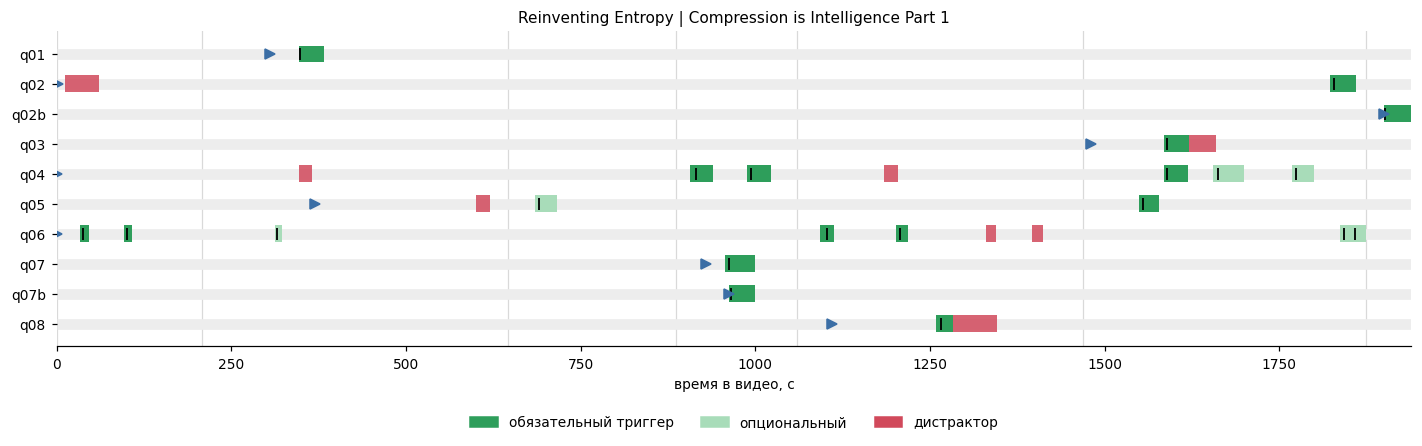

In [5]:
COL_REQ, COL_OPT, COL_DIS = "#2e9e5b", "#a8dcb9", "#d1495b"

def draw_chapters(ax, dur):
    for c in B["chapters"]:
        ax.axvline(c["start"], color="0.85", lw=0.8, zorder=0)
    ax.set_xlim(0, dur)

def global_map(samples=S, figsize=(13, 4.2)):
    dur = B["duration"]
    fig, ax = plt.subplots(figsize=figsize)
    draw_chapters(ax, dur)
    for i, s in enumerate(samples):
        y = len(samples) - 1 - i
        ax.hlines(y, 0, dur, color="0.93", lw=7, zorder=1)
        for d in s.get("distractor_windows", []):
            ax.barh(y, d["t_end"] - d["t_start"], left=d["t_start"], height=0.55,
                    color=COL_DIS, alpha=0.85, zorder=2)
        for t in s["triggers"]:
            ax.barh(y, max(t["t_end"] - t["t_start"], 4), left=t["t_start"], height=0.55,
                    color=COL_REQ if t["required"] else COL_OPT, zorder=3)
            ax.plot(t["t_ideal"], y, "|", color="black", ms=8, mew=1.2, zorder=4)
        ax.plot(s["question_time"], y, ">", color="#3b6ea5", ms=6, zorder=4)
    ax.set_yticks(range(len(samples)))
    ax.set_yticklabels([s["id"].split("__")[-1] for s in reversed(samples)])
    ax.set_xlabel("время в видео, с")
    ax.set_title(B["title"], fontsize=10)
    ax.legend(handles=[
        Patch(color=COL_REQ, label="обязательный триггер"),
        Patch(color=COL_OPT, label="опциональный"),
        Patch(color=COL_DIS, label="дистрактор"),
    ], loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    plt.tight_layout()
    plt.show()

global_map()

## Покрытие по осям таксономии

Здесь важно смотреть не на красоту, а на дыры: пустая ячейка куба
(акт × отношение × уровень) — это то, что ещё не размечено.

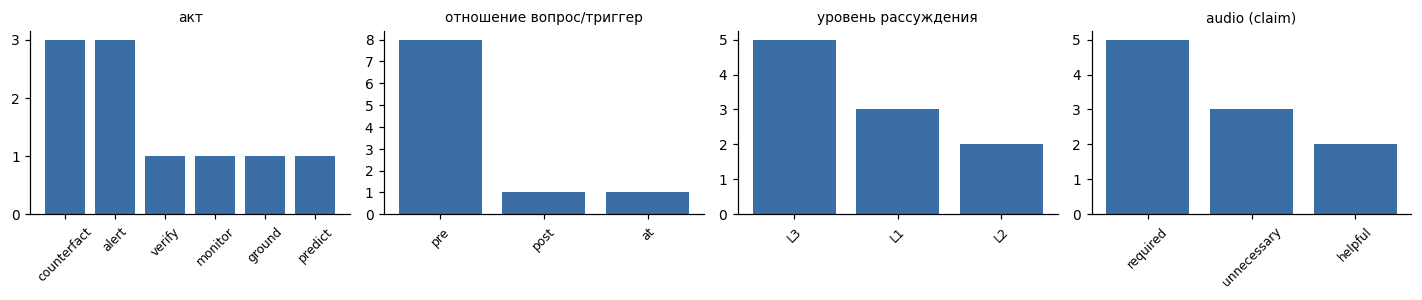

col_0                  L1  L2  L3
акт         отношение            
alert       post        1   0   0
            pre         1   1   0
counterfact at          0   0   1
            pre         0   0   2
ground      pre         1   0   0
monitor     pre         0   1   0
predict     pre         0   0   1
verify      pre         0   0   1

In [6]:
def coverage(samples=S):
    fields = [("act", "акт"), ("temporal_rel", "отношение вопрос/триггер"),
              ("reasoning_level", "уровень рассуждения"), ("audio_dependency_claim", "audio (claim)")]
    fig, axes = plt.subplots(1, len(fields), figsize=(13, 2.8))
    for ax, (f, title) in zip(axes, fields):
        vc = pd.Series([s.get(f) for s in samples]).value_counts()
        ax.bar(vc.index.astype(str), vc.values, color="#3b6ea5")
        ax.set_title(title, fontsize=9)
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        ax.set_yticks(range(0, max(vc.values) + 1))
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.show()

    cube = pd.crosstab(
        [ [s["act"] for s in samples], [s["temporal_rel"] for s in samples] ],
        [s["reasoning_level"] for s in samples])
    cube.index.names = ["акт", "отношение"]
    return cube

coverage()

## Детальный просмотр вопроса по индексу

`show(i)` — всё про один сэмпл. `show(i, frames=False)` — без кадров (быстрее),
`show(i, context=8)` — сколько секунд транскрипта показывать вокруг окна.

In [7]:
def timeline(s, figsize=(12, 1.5)):
    dur = s["video"]["duration"]
    fig, ax = plt.subplots(figsize=figsize)
    draw_chapters(ax, dur)
    ax.hlines(0, 0, dur, color="0.93", lw=16, zorder=1)
    for d in s.get("distractor_windows", []):
        ax.barh(0, d["t_end"] - d["t_start"], left=d["t_start"], height=0.6,
                color=COL_DIS, alpha=0.85, zorder=2)
    for t in s["triggers"]:
        ax.barh(0, max(t["t_end"] - t["t_start"], 4), left=t["t_start"], height=0.6,
                color=COL_REQ if t["required"] else COL_OPT, zorder=3)
        ax.plot(t["t_ideal"], 0, "|", color="black", ms=14, mew=1.4, zorder=4)
        ax.annotate(str(t["idx"]), (t["t_ideal"], 0.42), ha="center", fontsize=8)
    ax.plot(s["question_time"], 0, ">", color="#3b6ea5", ms=9, zorder=4)
    ax.set_ylim(-0.6, 0.7); ax.set_yticks([])
    ax.set_xlabel("время в видео, с")
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.show()


def show(i, frames=True, context=6.0, samples=None):
    s = (samples or S)[i]
    print("=" * 104)
    print(f"[{i}] {s['id']}")
    print(f"     {s['template']}  |  {s['act']} / {s['temporal_rel']} / {s['reasoning_level']}"
          f"  |  audio claim={s.get('audio_dependency_claim')}, замер={s['audio_dependency']}"
          f"  |  статус={s['validation']['status']}")
    print("-" * 104)
    print("ВОПРОС (выдан на", f"{s['question_time']:.0f} с):")
    print(wrap(s["question"], indent="  "))
    if s["validation"].get("notes"):
        print("\nЗАМЕТКА РАЗМЕТЧИКА:")
        print(wrap(s["validation"]["notes"], indent="  "))

    timeline(s)

    for d in s.get("distractor_windows", []):
        print(f"\n  ✗ ДИСТРАКТОР [{d['t_start']:.0f}, {d['t_end']:.0f})")
        print(wrap(d["why"], indent="      "))

    for t in s["triggers"]:
        mark = "●" if t["required"] else "○"
        print("\n" + "-" * 104)
        print(f"  {mark} ТРИГГЕР {t['idx']}  [{t['t_start']:.1f}, {t['t_end']:.1f})  "
              f"t_ideal={t['t_ideal']:.1f}  модальности={'+'.join(t['trigger_modality'])}"
              + (f"  depends_on={t['depends_on']}" if t.get("depends_on") else "")
              + ("" if t["required"] else "  (опциональный)"))
        print(f"    чаптер: {chapter_at(t['t_ideal'])}")
        print("\n    ЭТАЛОННЫЙ ОТВЕТ:")
        print(wrap(t["response"], indent="      "))
        print("\n    РУБРИКА:")
        for r in t["rubric"]:
            print(wrap(("— " + r), indent="      "))
        cues = transcript_at(t["t_start"], t["t_end"], pad=context)
        if cues:
            print("\n    ТРАНСКРИПТ ВОКРУГ ОКНА:")
            for c in cues:
                inside = t["t_start"] <= c["start"] < t["t_end"]
                print(f"      {'>' if inside else ' '} {c['start']:7.1f}  {c['text']}")
        if frames:
            show_frames(t)

    print("\n    ИСТОЧНИКИ (provenance.evidence):")
    for e in s["provenance"]["evidence"]:
        print(wrap("— " + e, indent="      "))


def show_frames(t):
    ts = sorted({t["t_start"] + 0.5, t["t_ideal"], max(t["t_end"] - 0.5, t["t_ideal"])})
    fig, axes = plt.subplots(1, len(ts), figsize=(4.1 * len(ts), 2.6))
    axes = [axes] if len(ts) == 1 else list(axes)
    for ax, tt in zip(axes, ts):
        ax.imshow(plt.imread(frame_at(tt)))
        ax.set_title(f"t = {tt:.1f} с" + ("  ← t_ideal" if abs(tt - t["t_ideal"]) < 1e-6 else ""),
                     fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.show()

[0] 3b1b__l6DKRf-fAAM__q01
     counterfactual_on_appearance  |  counterfact / pre / L3  |  audio claim=unnecessary, замер=None  |  статус=draft
--------------------------------------------------------------------------------------------------------
ВОПРОС (выдан на 305 с):
  Как только на экране появится таблица кодовых слов, которую предлагает «сообразительный» студент,
    посчитай сам и скажи: каким стало бы среднее число бит на инструкцию, если поменять местами
    кодовые слова, назначенные инструкции «вверх» и инструкции «влево», оставив вероятности
    прежними?

ЗАМЕТКА РАЗМЕТЧИКА:
  контрфактика намеренно неканоническая: 2.5 нет ни в видео, ни в учебниках


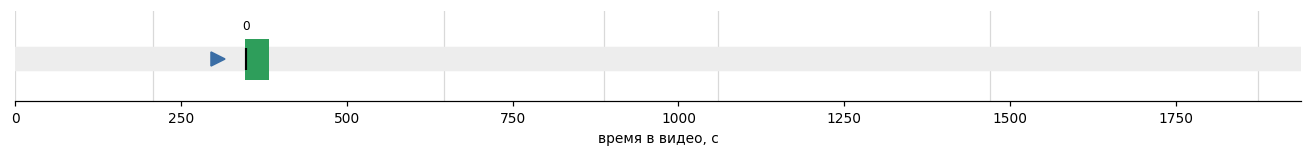


--------------------------------------------------------------------------------------------------------
  ● ТРИГГЕР 0  [347.0, 382.0)  t_ideal=348.0  модальности=visual
    чаптер: The warmup example

    ЭТАЛОННЫЙ ОТВЕТ:
      2.5 бита на инструкцию. После обмена «вверх» (p=1/2) кодируется тремя битами 110, а «влево»
        (p=1/8) — одним битом 0, поэтому среднее равно 1/2·3 + 1/4·2 + 1/8·1 + 1/8·3 = 2.5. Это хуже
        не только исходных 1.75, но и наивного равномерного кода в 2 бита.

    РУБРИКА:
      — названо число 2.5 (или 2.5 бита на инструкцию)
      — показан или описан взвешенный расчёт с вероятностями 1/2, 1/4, 1/8, 1/8 и длинами 3, 2, 1, 3
      — засчитывать как полный ответ только при явном указании, что результат хуже наивных 2 бит
      — НЕ засчитывать ответ 1.75 — это исходный код, а не переставленный

    ТРАНСКРИПТ ВОКРУГ ОКНА:
          337.2  What they suggest is letting the single bit 0 represent up,
          341.3  letting the two bits 10 represent down

In [8]:
show(0, frames=False)

### Пример: q02 — ловушка на преждевременный ответ

Верное число «1.0 bits/ch» висит на экране на 40-й секунде с подписью «Limit?»,
а настоящий ответ звучит только на 1822-й. Оба ранних окна размечены как дистракторы.

[1] 3b1b__l6DKRf-fAAM__q02
     premature_answer_trap  |  alert / pre / L1  |  audio claim=required, замер=None  |  статус=draft
--------------------------------------------------------------------------------------------------------
ВОПРОС (выдан на 2 с):
  Дождись момента, когда автор назовёт оценку Шеннона для предела сжатия английского языка, и скажи
    одновременно две вещи: само число и при каком объёме предшествующего контекста эта оценка
    получена. Пока не прозвучит именно оценка Шеннона — молчи.

ЗАМЕТКА РАЗМЕТЧИКА:
  ключевой сэмпл на timing: верное число видно на экране за 1785 с до ответа; уровень L1: оба факта
    звучат в одной реплике 1822-1829, сложность сэмпла целиком в тайминге, а не в рассуждении


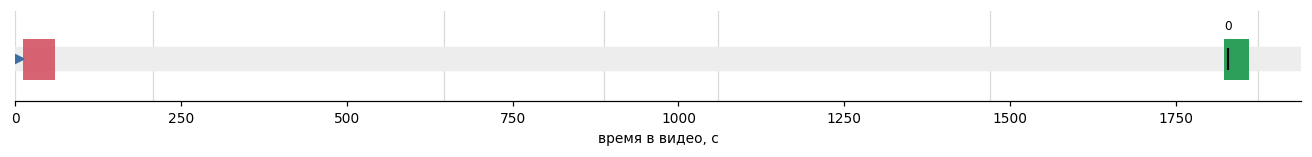


  ✗ ДИСТРАКТОР [12, 34)
      на экране идёт ряд ASCII 8.0 -> Huffman ~4.2 -> Neural methods ~1.1 бит/символ; это достижения
        методов сжатия, а не оценка Шеннона

  ✗ ДИСТРАКТОР [34, 60)
      на экране спидометр со значением 1.0 bits/ch и подписью «Limit?» — число совпадает с верным
        ответом, но это постановка вопроса, а не ответ, и без условий получения

--------------------------------------------------------------------------------------------------------
  ● ТРИГГЕР 0  [1822.0, 1860.0)  t_ideal=1829.0  модальности=speech+visual
    чаптер: Defining Entropy

    ЭТАЛОННЫЙ ОТВЕТ:
      Около одного бита на символ; оценка получена, когда у людей-угадывателей было не менее 100
        предшествующих букв контекста.

    РУБРИКА:
      — названа величина ≈1 бит на символ
      — названо условие: не менее 100 предшествующих символов контекста
      — указано, что это оценка по экспериментам с людьми, а не измерение алгоритмом
      — ответ только с числом, без условия про

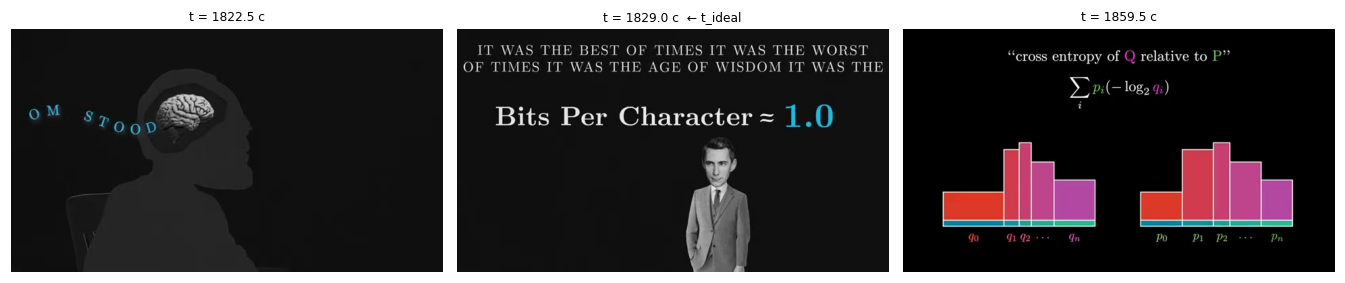


    ИСТОЧНИКИ (provenance.evidence):
      — речь 1822.0-1829.4: «at least 100 preceding letters of context ... about one bit per
        character»
      — кадр t=1832: счётчик «Bits Per Character ≈ 1.0»
      — кадр t=15: ASCII 8.0 bits/ch; t=21: Huffman ~4.2; t=30: Neural ~1.1
      — кадр t=40: спидометр 1.0 bits/ch с подписью Limit?


In [9]:
show(idx_of("q02"))

### Пример: q04 — многотриггерный мониторинг

Пять окон, у поздних `depends_on` на ранние: ответ обязан перечислить всё
накопленное к этому моменту.

[4] 3b1b__l6DKRf-fAAM__q04
     state_monitor  |  monitor / pre / L2  |  audio claim=helpful, замер=None  |  статус=draft
--------------------------------------------------------------------------------------------------------
ВОПРОС (выдан на 0 с):
  Следи за тем, какие величины автор определяет формально — то есть выписывает для них формулу или
    даёт имя. Каждый раз, когда добавляется новая, перечисли все определённые к этому моменту
    величины в порядке появления и скажи для новой, из чего она получена.

ЗАМЕТКА РАЗМЕТЧИКА:
  многотриггерный сэмпл; проверяет накопление состояния и depends_on


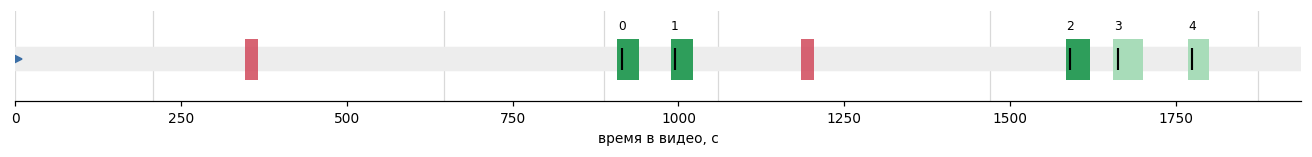


  ✗ ДИСТРАКТОР [347, 366)
      взвешенная сумма для среднего числа бит у робота — это арифметика конкретного примера, а не
        введение формально определённой величины

  ✗ ДИСТРАКТОР [1184, 1204)
      цепное правило и свойство логарифма — используемые факты, а не новые определения

--------------------------------------------------------------------------------------------------------
  ● ТРИГГЕР 0  [907.0, 940.0)  t_ideal=915.0  модальности=visual+speech
    чаптер: Defining information

    ЭТАЛОННЫЙ ОТВЕТ:
      Определено: (1) число бит на сообщение при идеальном сжатии = -log2(p). Получено
        логарифмированием и сменой знака у соотношения p = 1/2^n, которое следует из того, что все
        2^n сообщений равновероятны.

    РУБРИКА:
      — названа формула -log2(p) (или log2(1/p))
      — указано, что она получена из p = 2^(-n) взятием логарифма
      — список содержит одну величину; упоминание вспомогательного соотношения P(n-битного
        сообщения) = 1/2^n ошибкой

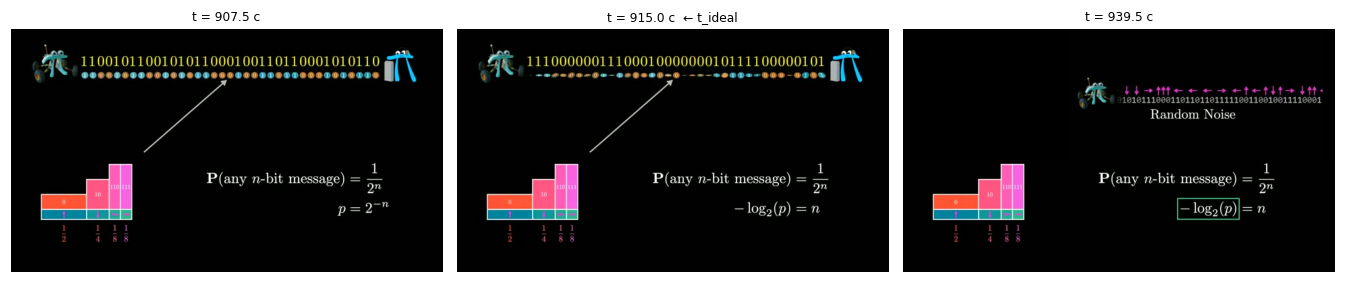


--------------------------------------------------------------------------------------------------------
  ● ТРИГГЕР 1  [988.0, 1022.0)  t_ideal=994.0  модальности=speech  depends_on=[0]
    чаптер: Defining information

    ЭТАЛОННЫЙ ОТВЕТ:
      Определено: (1) число бит = -log2(p); (2) информация события — Шеннон определяет тем же
        выражением -log2(p), но уже для любых p, а не только для степеней двойки.

    РУБРИКА:
      — названа информация события
      — указано, что это то же выражение, обобщённое на нецелые значения
      — перечислены обе величины в правильном порядке

    ТРАНСКРИПТ ВОКРУГ ОКНА:
          982.6  when literal perfect compression is not possible and p is no longer a clean power of 2,
          987.4  which would mean that the output here is some fractional amount.
      >   991.3  In fact, he defined this expression to be the information of an event.
      >   996.2  The image I sometimes have in my head is to picture the probability of an event
    

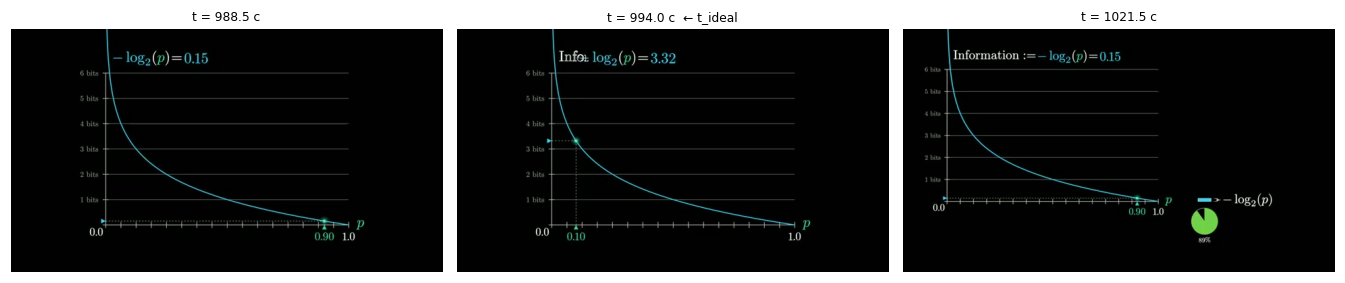


--------------------------------------------------------------------------------------------------------
  ● ТРИГГЕР 2  [1585.0, 1620.0)  t_ideal=1590.0  модальности=visual+speech  depends_on=[0, 1]
    чаптер: Defining Entropy

    ЭТАЛОННЫЙ ОТВЕТ:
      Определено: (1) число бит = -log2(p); (2) информация события; (3) средняя информация на символ
        = sum_i p_i·(-log2 p_i). Получена усреднением информации отдельных символов по их
        вероятностям.

    РУБРИКА:
      — названа формула суммы p·(-log p)
      — указано, что это взвешенное среднее информации по распределению
      — перечислены все три величины в правильном порядке

    ТРАНСКРИПТ ВОКРУГ ОКНА:
         1577.7  messages are made out of, the average information per symbol should look like
         1582.5  adding up p times the negative log of p for each probability p in that distribution.
      >  1588.5  And take a moment to notice how we're visualizing this expression.
      >  1592.0  Throughout the video, we

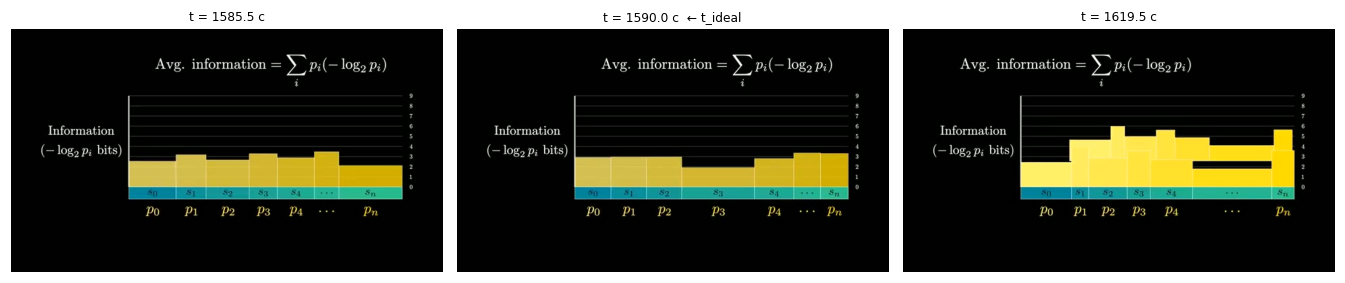


--------------------------------------------------------------------------------------------------------
  ○ ТРИГГЕР 3  [1655.0, 1700.0)  t_ideal=1663.0  модальности=speech  depends_on=[2]  (опциональный)
    чаптер: Defining Entropy

    ЭТАЛОННЫЙ ОТВЕТ:
      Новой формулы нет, но величина из предыдущего пункта получает имя «энтропия» и обозначение H.

    РУБРИКА:
      — указано, что это именование уже введённой величины, а не новая формула
      — названы имя «энтропия» и обозначение H

    ТРАНСКРИПТ ВОКРУГ ОКНА:
         1648.6  mechanics, and for another, quote, nobody knows what entropy really is,
         1652.5  so in an argument, you'll always have the advantage.
      >  1655.3  I looked into it, it's probably apocryphal, but
      >  1657.7  there seems to be a grain of truth to this.
      >  1660.6  Now, whatever the true story is, Shannon did call this quantity entropy,
      >  1664.6  and he denoted it with the letter h.
      >  1667.2  And it's fun to take a momen

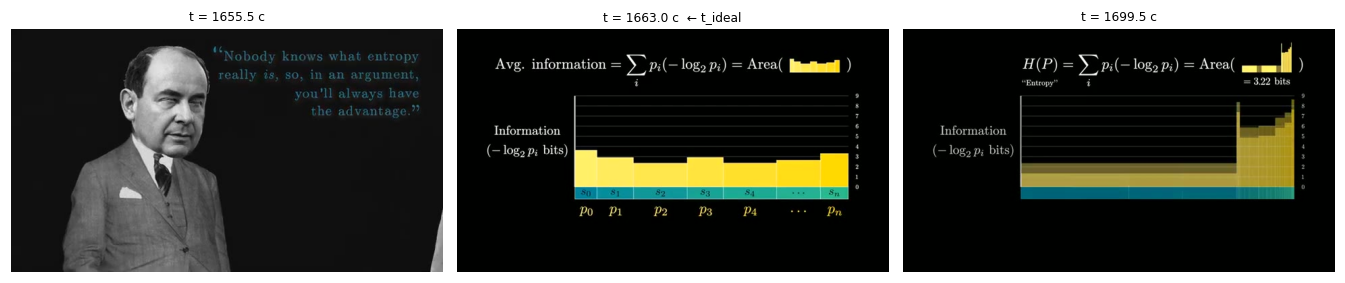


--------------------------------------------------------------------------------------------------------
  ○ ТРИГГЕР 4  [1768.0, 1800.0)  t_ideal=1774.0  модальности=speech  depends_on=[2]  (опциональный)
    чаптер: Defining Entropy

    ЭТАЛОННЫЙ ОТВЕТ:
      Упомянута энтропийная скорость (entropy rate) стохастического процесса — обобщение на случай,
        когда распределение символов меняется; формула не выписана.

    РУБРИКА:
      — названа entropy rate
      — отмечено, что формула не приводится

    ТРАНСКРИПТ ВОКРУГ ОКНА:
         1764.7  In particular, he spent a ton of time contemplating
         1767.6  the compressibility of natural language.
      >  1770.5  This requires a more general notion of entropy,
      >  1772.8  something known as the entropy rate for a stochastic process.
      >  1776.4  But it's the same basic question.
      >  1778.2  What is the average information per symbol, except in
      >  1781.2  this case we're now averaging over all possible m

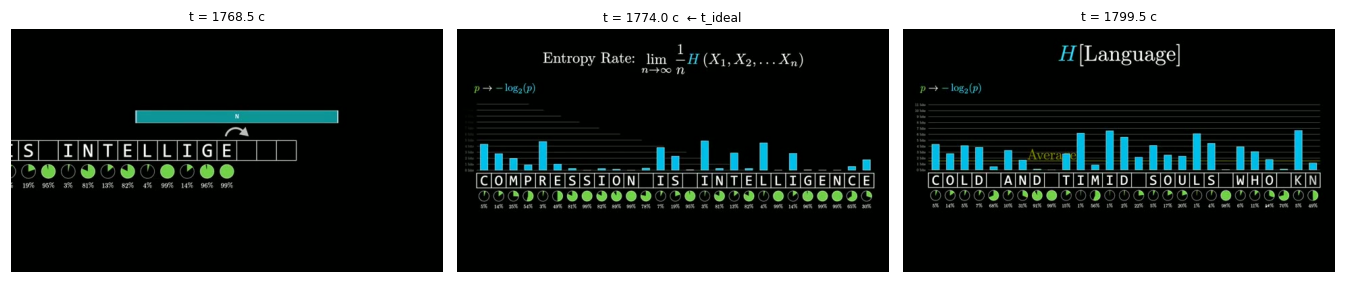


    ИСТОЧНИКИ (provenance.evidence):
      — кадр t=920: на экране P(any n-bit message)=1/2^n и -log2(p)=n
      — речь 907.6-922.2
      — речь 991.3-996.2
      — речь 1573.1-1587
      — речь 1660.6-1665
      — речь 1770.5-1776.4


In [10]:
show(idx_of("q04"), context=3)

try:
    from ipywidgets import interact, IntSlider, Checkbox
    interact(lambda i, frames, context: show(i, frames=frames, context=context),
             i=IntSlider(min=0, max=len(S) - 1, step=1, value=0, description="вопрос"),
             frames=Checkbox(value=True, description="кадры"),
             context=IntSlider(min=0, max=20, step=1, value=6, description="контекст, с"))
except ImportError as e:
    print("виджеты недоступны:", e)
    print("используй show(i) вручную, i от 0 до", len(S) - 1)

In [11]:
def browse(samples=None):
    # слайдер по вопросам; под nbconvert не вызывать — блокирует ядро
    from ipywidgets import interact, IntSlider, Checkbox
    data = samples or S
    return interact(
        lambda i, frames, context: show(i, frames=frames, context=context, samples=data),
        i=IntSlider(min=0, max=len(data) - 1, step=1, value=0, description="вопрос"),
        frames=Checkbox(value=True, description="кадры"),
        context=IntSlider(min=0, max=20, step=1, value=6, description="контекст, с"),
    )

In [ ]:
browse()

## Что рядом в bundle

Помимо разметки под рукой есть материалы, из которых она делалась.

In [12]:
# формулы, выдранные из manim-исходника: полезно, когда размечаешь «что на экране»
pd.DataFrame(B["formulas"]).head(15)

,file,line,scene,call,text
0,_2026/cross_entropy/arithmetic_coding.py,390,ProbababilityOfAWord,Tex,P(``math\
1,_2026/cross_entropy/entropy.py,99,CompressibilitOfText,Tex,\vdots
2,_2026/cross_entropy/entropy.py,133,CompressibilitOfText,Tex,\rightarrow
3,_2026/cross_entropy/entropy.py,137,CompressibilitOfText,Tex,\sim 8.0 \text{bits} / \text{ch}
4,_2026/cross_entropy/entropy.py,146,CompressibilitOfText,Text,ASCII
5,_2026/cross_entropy/entropy.py,147,CompressibilitOfText,Text,Huffman
6,_2026/cross_entropy/entropy.py,148,CompressibilitOfText,Text,Neural methods
7,_2026/cross_entropy/entropy.py,251,SpaceOfCodewords,Tex,\vdots
8,_2026/cross_entropy/entropy.py,292,SpaceOfCodewords,TexText,{n + 1} bit{
9,_2026/cross_entropy/entropy.py,515,IntroduceRandomNoise,Text,Random Noise


In [13]:
# чаптеры и их длительность
ch = pd.DataFrame(B["chapters"])
ch["длит., с"] = (ch["end"] - ch["start"]).round(1)
ch

,start,end,title,"длит., с"
0,0,208,On “Compression is intelligence.”,208
1,208,646,The warmup example,438
2,646,887,What perfect compression looks like,241
3,887,1060,Defining information,173
4,1060,1469,Information of language,409
5,1469,1874,Defining Entropy,405
6,1874,1939,3b1b Talent,65
